# EuroSAT: optical multispectral imagery
 One Colab per team: **work in this notebook together** (share it with edit rights, each member keeps a copy as backup).
Write short markdown notes as you go: they are the basis of your report and your oral defense.



## Présentation de l’étude

Cette étude porte sur la classification de patches multispectraux EuroSAT en dix classes d’occupation du sol. Chaque patch est représenté par 26 caractéristiques : la moyenne et l’écart-type de chacune des treize bandes.

La méthode associe un centrage-réduction par StandardScaler à une forêt aléatoire. Les paramètres sont sélectionnés sur un ensemble de validation ; l’évaluation utilise un ensemble de test séparé spatialement. Les performances sont analysées avec le F1 macro, l’accuracy, les résultats par classe et les principales confusions.

# A. Setup

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
SEED = 0; np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [ ]:
import importlib.util
import subprocess
import sys
for module, paquet in [("rasterio", "rasterio"), ("sklearn", "scikit-learn"),
                        ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquet])

from pathlib import Path
import hashlib
import json
import time
import urllib.request
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GroupShuffleSplit, ParameterGrid
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
import sklearn

# Fixer la graine rend les tirages aléatoires reproductibles.
GRAINE = 0
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                    "axes.spines.right": False})
print("Python :", sys.version.split()[0], "| scikit-learn :", sklearn.__version__)

Python : 3.12.2 | scikit-learn : 1.8.0


## 1. Data

**EuroSAT** (Sentinel-2, 64x64 px patches, 13 spectral bands, 10 land-cover classes, about 27,000 patches, MIT licence).
Source: https://zenodo.org/records/7711810

### 1.1 Download
Run the cell below once (download takes a few minutes).

In [ ]:
!apt-get -qq install -y aria2 > /dev/null
!rm -rf EuroSAT_MS EuroSAT_MS.zip EuroSAT_MS.*.zip
!aria2c -x 16 -s 16 -k 4M --allow-overwrite=true --auto-file-renaming=false --console-log-level=warn --summary-interval=30 -o EuroSAT_MS.zip https://zenodo.org/records/7711810/files/EuroSAT_MS.zip
!unzip -q -o EuroSAT_MS.zip -d EuroSAT_MS
!pip -q install rasterio
!ls EuroSAT_MS/EuroSAT_MS | head -12          # the zip contains an extra folder: one sub-folder per class, patches are .tif files
!ls EuroSAT_MS/EuroSAT_MS/Forest | head -3

 *** Download Progress Summary as of Thu Nov  5 16:23:21 2026 *** 
=
[#4664ef 508MiB/1.9GiB(25%) CN:16 DL:19MiB ETA:1m15s]
FILE: /content/EuroSAT_MS.zip
-

 *** Download Progress Summary as of Thu Nov  5 16:23:52 2026 *** 
=
[#4664ef 1.3GiB/1.9GiB(69%) CN:16 DL:29MiB ETA:20s]
FILE: /content/EuroSAT_MS.zip
-

 *** Download Progress Summary as of Thu Nov  5 16:24:23 2026 *** 
=
[#4664ef 1.9GiB/1.9GiB(99%) CN:3 DL:4.0MiB]
FILE: /content/EuroSAT_MS.zip
-


Download Results:
gid   |stat|avg speed  |path/URI
======+====+===========+=======================================================
4664ef|OK  |    20MiB/s|/content/EuroSAT_MS.zip

Status Legend:
(OK):download completed.
EuroSAT_MS


In [25]:
# Répertoire des images et archive du jeu de données.
DOSSIER = Path("EuroSAT_MS/EuroSAT_MS")
ARCHIVE = Path("EuroSAT_MS.zip")
URL = "https://zenodo.org/records/7711810/files/EuroSAT_MS.zip"
MD5_ATTENDU = "091174add3c8e680a49244acf185b9f0"

if not DOSSIER.exists() or len(list(DOSSIER.glob("*/*.tif"))) != 27000:
    if not ARCHIVE.exists():
        print("Téléchargement d’environ 2 Go…")
        urllib.request.urlretrieve(URL, ARCHIVE)
    empreinte = hashlib.md5()
    with ARCHIVE.open("rb") as fichier:
        for bloc in iter(lambda: fichier.read(8 * 1024 * 1024), b""):
            empreinte.update(bloc)
    if empreinte.hexdigest() != MD5_ATTENDU:
        raise ValueError("Archive incomplète : supprimer EuroSAT_MS.zip puis relancer.")
    with zipfile.ZipFile(ARCHIVE) as archive:
        archive.extractall("EuroSAT_MS")
print("Dossier disponible :", DOSSIER)

Dossier disponible : EuroSAT_MS\EuroSAT_MS


### 1.2. Look at the data

No model yet. Use plots and short statistics to answer, in your own words (add cells as you need):

- How is the data organised (folders, file format, number of bands, value range)? Open a few patches and display them (RGB = bands 4-3-2).
- How many patches per class? What does the mean spectrum of each class look like? Which classes look alike?
- What would be a *feature* here: raw pixels, band statistics, indices, texture...?

*Your notes:*

### Exploration des données

**Organisation.** Le jeu comprend **27 000 patches**, répartis dans **dix dossiers de classes**. Chaque fichier est une image TIFF de **64 × 64 pixels et 13 bandes spectrales**. Les compositions en couleurs utilisent les bandes 4, 3 et 2, avec un ajustement du contraste pour rendre les images lisibles.

**Effectifs.** AnnualCrop, Forest, HerbaceousVegetation, Residential et SeaLake comptent chacune 3 000 images ; Highway, Industrial, PermanentCrop et River en comptent chacune 2 500 ; Pasture en compte 2 000. Les classes sont donc modérément déséquilibrées. Nous présentons le F1 macro et les résultats par classe pour compléter l’accuracy globale.

**Valeurs et spectres.** Les 30 images par classe examinées pendant l’exploration donnent des valeurs de **2 à 24 149**. Le passage ultérieur sur les **27 000 images** trouve un minimum de **0** et un maximum de **28 003**. La différence vient du périmètre examiné. Les spectres sont des moyennes estimées sur l’échantillon ; une proximité entre deux courbes suggère une difficulté possible, mais ne démontre pas une erreur de classification.

**Caractéristiques.** Un patch contient **4 096 pixels**, chacun décrit par 13 valeurs spectrales, soit **53 248 valeurs au total**. Nous le résumons par **13 moyennes et 13 écarts-types**, soit **26 caractéristiques**. Les moyennes décrivent les niveaux spectraux et les écarts-types la variation interne. Cette représentation compacte perd toutefois la position et la forme des objets.

**Lecture des spectres moyens.** Dans les graphiques de notre échantillon, SeaLake présente des valeurs généralement plus faibles. AnnualCrop et Pasture se ressemblent sur plusieurs bandes, notamment 6 à 8 et 13. Cette ressemblance spectrale suggère une proximité, sans démontrer à elle seule une confusion du classificateur.


AnnualCrop : 3000 patches
Forest : 3000 patches
HerbaceousVegetation : 3000 patches
Highway : 2500 patches
Industrial : 2500 patches
Pasture : 2000 patches
PermanentCrop : 2500 patches
Residential : 3000 patches
River : 2500 patches
SeaLake : 3000 patches
Format : GTiff
Nombre de bandes : 13
Taille : 64 × 64 pixels


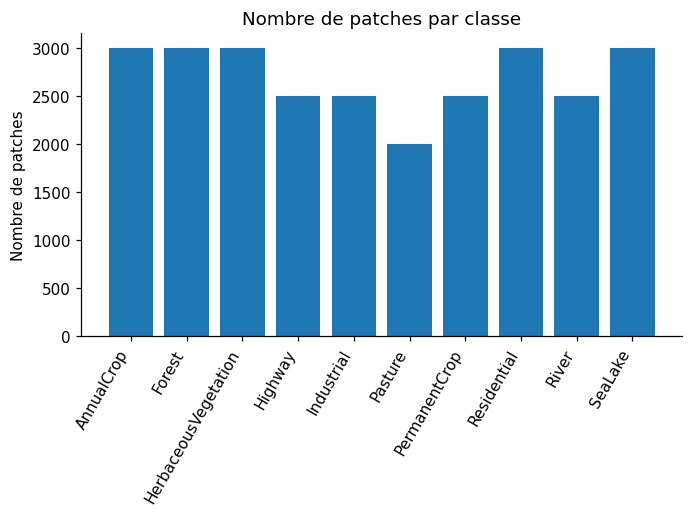

In [26]:
from pathlib import Path
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Répertoire des patches multispectraux.
dossier_principal = Path("EuroSAT_MS/EuroSAT_MS")

# Chaque sous-dossier correspond à une classe.
dossiers_classes = sorted(
    dossier for dossier in dossier_principal.iterdir() if dossier.is_dir()
)

# On récupère la liste des fichiers .tif de chaque classe.
fichiers_par_classe = {
    dossier.name: sorted(dossier.glob("*.tif"))
    for dossier in dossiers_classes
}

# On affiche le nombre de patches de chaque classe.
for nom_classe, fichiers in fichiers_par_classe.items():
    print(f"{nom_classe} : {len(fichiers)} patches")

# On ouvre une image pour vérifier son format, sa taille et ses bandes.
premier_fichier = next(iter(fichiers_par_classe.values()))[0]
with rasterio.open(premier_fichier) as image:
    print("Format :", image.driver)
    print("Nombre de bandes :", image.count)
    print("Taille :", image.width, "×", image.height, "pixels")

# Ce graphique permet de comparer le nombre de patches par classe.
plt.bar(
    fichiers_par_classe.keys(),
    [len(fichiers) for fichiers in fichiers_par_classe.values()]
)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Nombre de patches")
plt.title("Nombre de patches par classe")
plt.tight_layout()
plt.show()

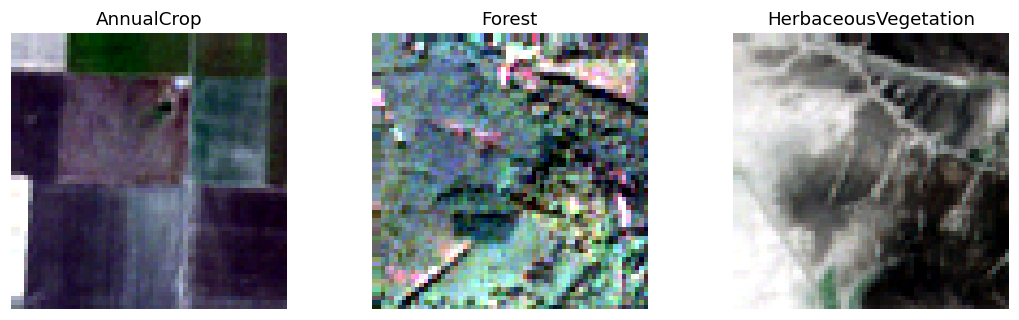

In [4]:
# On affiche un patch de trois classes différentes.
figure, axes = plt.subplots(1, 3, figsize=(10, 3))

for axe, (nom_classe, fichiers) in zip(
    axes, list(fichiers_par_classe.items())[:3]
):
    with rasterio.open(fichiers[0]) as image:
        # Les bandes 4, 3 et 2 représentent le rouge, le vert et le bleu.
        rgb = image.read([4, 3, 2]).transpose(1, 2, 0).astype(float)

    # On ajuste les valeurs pour que l'image soit visible à l'écran.
    minimum = np.percentile(rgb, 2, axis=(0, 1))
    maximum = np.percentile(rgb, 98, axis=(0, 1))
    rgb = np.clip((rgb - minimum) / (maximum - minimum + 1e-9), 0, 1)

    axe.imshow(rgb)
    axe.set_title(nom_classe)
    axe.axis("off")

plt.tight_layout()
plt.show()

Valeurs observées dans l'échantillon : 2 à 24149


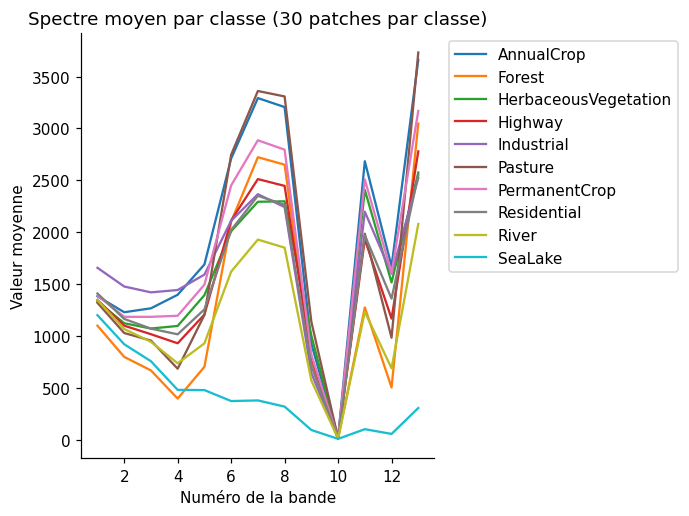

In [5]:
# On utilise 30 images par classe pour que le calcul reste rapide.
generateur = np.random.default_rng(0)
spectres_moyens = {}
valeur_minimale = np.inf
valeur_maximale = -np.inf

for nom_classe, fichiers in fichiers_par_classe.items():
    echantillon = generateur.choice(
        fichiers, size=min(30, len(fichiers)), replace=False
    )
    spectres = []

    for fichier in echantillon:
        with rasterio.open(fichier) as image:
            donnees = image.read()

        # On relève les valeurs extrêmes des images examinées.
        valeur_minimale = min(valeur_minimale, donnees.min())
        valeur_maximale = max(valeur_maximale, donnees.max())

        # Une moyenne est calculée pour chacune des 13 bandes du patch.
        spectres.append(donnees.mean(axis=(1, 2)))

    # On calcule ensuite le spectre moyen de cette classe.
    spectres_moyens[nom_classe] = np.mean(spectres, axis=0)

print("Valeurs observées dans l'échantillon :",
      valeur_minimale, "à", valeur_maximale)

# Chaque courbe représente le spectre moyen d'une classe.
for nom_classe, spectre in spectres_moyens.items():
    plt.plot(range(1, len(spectre) + 1), spectre, label=nom_classe)

plt.xlabel("Numéro de la bande")
plt.ylabel("Valeur moyenne")
plt.title("Spectre moyen par classe (30 patches par classe)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 2. Formulate your objective

Before choosing a method, decide **what question you answer**. Discuss as a team and write your answer below.

- What is the *unit* you want to classify (a patch? a pixel?) and what do you want to predict?
- Which confusions would matter most for an end-user (e.g. a land-cover map for agriculture vs for urban planning)?
- Which metric reflects your objective (accuracy, per-class F1, ...)? What is a reasonable baseline?
- What are the limits of the data (spatial coverage, labelling, patches vs maps) and what claim can you therefore support?

**Objective (3-5 sentences):**

**Target / unit of analysis:**

**Metric(s) and baseline:**

**Main risk of a misleading result:**

*Show this paragraph to your supervisor before going further.*

### Objectif de classification

**Question étudiée :**

What is the *unit* you want to classify (a patch? a pixel?) and what do you want to predict?

L’unité à classifier est **un patch entier de 64 × 64 pixels contenant 13 bandes spectrales**. Nous voulons prédire **sa classe d’occupation du sol parmi les dix classes d’EuroSAT**, par exemple Forest, AnnualCrop ou Residential. Nous attribuons une seule étiquette à l’ensemble du patch ; il ne s’agit pas d’une classification de chaque pixel.

**Objective — Objectif :**

Notre objectif est de prédire la classe d’occupation du sol d’un patch entier d’EuroSAT parmi les dix classes disponibles. Nous représentons chaque patch par la moyenne et l’écart-type de ses treize bandes spectrales, soit 26 caractéristiques. Nous normalisons ces caractéristiques avec StandardScaler dans une pipeline suivie d’une forêt aléatoire. Nous choisissons les paramètres sur la validation avec le F1 macro, puis évaluons le modèle sur un test spatialement séparé en le comparant à une règle majoritaire.

**Target / unit of analysis — Cible / unité d’analyse :**

- **Unité :** un patch entier de 64 × 64 pixels et 13 bandes.
- **Cible :** une classe d’occupation du sol parmi les dix classes d’EuroSAT, prédite pour chaque patch.

**Metric(s) and baseline — Métriques et référence :**

- **Métrique principale :** le F1 macro, qui donne le même poids aux dix classes.
- **Métriques complémentaires :** l’accuracy, la précision, le rappel et le F1 par classe. Nous examinons aussi les confusions entre classes, notamment AnnualCrop / PermanentCrop pour les surfaces agricoles et Industrial / Residential pour les zones urbaines.
- **Référence :** prédire systématiquement la classe majoritaire des données ayant servi à l’apprentissage. Cette classe est déterminée sans utiliser les étiquettes de test.

**Main risk of a misleading result — Principal risque de résultat trompeur :**

Des patches voisins ou presque identiques dans l’apprentissage et le test peuvent donner une performance trop optimiste. Pour réduire ce risque, nous recherchons les copies exactes, séparons des blocs géographiques de 50 km et imposons au moins 2 km entre les centres des patches d’ensembles différents. La normalisation est ajustée sur l’apprentissage pendant la sélection, puis sur apprentissage + validation pour le modèle final, sans ajustement sur le test. Les patches peuvent contenir plusieurs types de surface malgré une seule étiquette ; les résultats du jeu étudié ne garantissent donc ni une carte classée pixel par pixel ni la même performance dans une autre région ou à une autre date.

# B. Classical Supervised Learning

Use the methods of the course to answer *your* objective. Suggested path (you decide the details):

1. **Choose** the methods from the course that fit your objective (SVM, decision tree, Random Forest, XGBoost, ...). Justify each choice in one sentence (data size, feature types, interpretability, cost).
2. **Build your evaluation protocol first**: train / validation / test split adapted to your data (see the warning above), metric(s), baseline. Freeze the test set.
3. **Train a baseline** (trivial rule or simple model), then your methods. Tune hyper-parameters on the validation set only (cross-validation that respects your split).
4. **Evaluate** on the test set once: metric(s) with an uncertainty estimate, confusion matrix or error analysis. Where does the model fail, and why?
5. **Interpret**: feature importances / permutation importance / examples of errors. Does the model rely on physically sensible information?
6. **Come back to your objective**: what can you conclude, with what confidence, and what would you do next (module 5/6: unsupervised, neural networks)?

> **Warning for your data.** Patches from the same area can be near-duplicates: think about how this affects your train/test split and about what 'generalising' means here

### Synthèse de la démarche

| Étape | Choix méthodologiques et résultats |
|---|---|
| 1. Choisir et justifier | Une pipeline **StandardScaler puis forêt aléatoire** sur les 26 statistiques de bandes. La forêt est notre seule famille de modèles supervisés. |
| 2. Définir le protocole | Blocs de 50 km et zone tampon de 2 km ; 16 995 patches d’apprentissage, 4 144 de validation et 5 528 de test. Le normaliseur apprend uniquement sur les données utilisées pour entraîner la pipeline. |
| 3. Entraîner et régler | Quatre configurations d’une forêt de 200 arbres ; meilleur F1 macro de validation : **0,8279**, avec profondeur non limitée et une observation au minimum par feuille. |
| 4. Évaluer sur le test | Réajustement de la normalisation et de la forêt sur apprentissage + validation, puis 84,15 % d’accuracy et 0,836 de F1 macro sur le test. |
| 5. Interpréter | Permutation sur la validation à travers la pipeline, puis inspection des erreurs. |
| 6. Revenir à l’objectif | Comparaison à la règle majoritaire, analyse des classes difficiles et limites de généralisation. |

Le tableau résume le protocole et les résultats présentés dans les sections suivantes.

In [27]:
# Définir les classes et la fonction d’affichage des patches.
classes = sorted(fichiers_par_classe)

def afficher_rgb(chemin):
    # Lire les trois bandes visibles puis ajuster le contraste pour l’affichage.
    with rasterio.open(chemin) as source:
        rgb = source.read([4, 3, 2]).transpose(1, 2, 0).astype(float)
    bas = np.percentile(rgb, 2, axis=(0, 1))
    haut = np.percentile(rgb, 98, axis=(0, 1))
    return np.clip((rgb - bas) / (haut - bas + 1e-9), 0, 1)


## 3. Extraire les caractéristiques et vérifier les doublons

Chaque ligne correspond à un patch. Nous calculons la moyenne et l’écart-type des treize bandes, puis vérifions les copies exactes avant la séparation des données.

In [14]:
# Préparer les noms des 26 caractéristiques.
noms_variables = ([f"moyenne_bande_{i}" for i in range(1, 14)] +
                  [f"ecart_type_bande_{i}" for i in range(1, 14)])
lignes = []
debut = time.perf_counter()
for nom, fichiers in fichiers_par_classe.items():
    for chemin in fichiers:
        with rasterio.open(chemin) as source:
            image = source.read()
            assert image.shape == (13, 64, 64)
            # Les coordonnées ne sont exploitables que si un CRS est présent.
            crs = str(source.crs) if source.crs else ""
            centre_x, centre_y = source.xy(32, 32)
        valeurs = np.concatenate([image.mean(axis=(1, 2)), image.std(axis=(1, 2))])
        ligne = dict(zip(noms_variables, valeurs))
        ligne.update(classe=nom, fichier=str(chemin),
                     empreinte=hashlib.sha256(image.tobytes()).hexdigest(),
                     minimum=int(image.min()), maximum=int(image.max()),
                     crs=crs, centre_x=centre_x, centre_y=centre_y)
        lignes.append(ligne)
    print(f"Caractéristiques calculées : {nom}")
table_complete = pd.DataFrame(lignes)
assert np.isfinite(table_complete[noms_variables].to_numpy()).all()

# Écarter les copies identiques ; si les étiquettes se contredisent, écarter le groupe.
nombre_labels = table_complete.groupby("empreinte")["classe"].nunique()
empreintes_ambigues = nombre_labels[nombre_labels > 1].index
nb_ambigus = table_complete.empreinte.isin(empreintes_ambigues).sum()
table = table_complete[~table_complete.empreinte.isin(empreintes_ambigues)].copy()
nb_copies = table.duplicated("empreinte").sum()
table = table.drop_duplicates("empreinte").reset_index(drop=True)
print(f"Copies exactes retirées : {nb_copies} ; images à étiquettes contradictoires : {nb_ambigus}")
print("Valeurs sur l’ensemble des 27 000 patches :", table_complete.minimum.min(),
      "à", table_complete.maximum.max())
print("Images avec un CRS :", int((table.crs != "").sum()), "/", len(table))
print("Durée de l’extraction :", round(time.perf_counter() - debut, 1), "secondes")
display(table[noms_variables + ["classe"]].head())

Caractéristiques calculées : AnnualCrop
Caractéristiques calculées : Forest
Caractéristiques calculées : HerbaceousVegetation
Caractéristiques calculées : Highway
Caractéristiques calculées : Industrial
Caractéristiques calculées : Pasture
Caractéristiques calculées : PermanentCrop
Caractéristiques calculées : Residential
Caractéristiques calculées : River
Caractéristiques calculées : SeaLake
Copies exactes retirées : 0 ; images à étiquettes contradictoires : 0
Valeurs sur l’ensemble des 27 000 patches : 0 à 28003
Images avec un CRS : 27000 / 27000
Durée de l’extraction : 628.0 secondes


,moyenne_bande_1,moyenne_bande_2,moyenne_bande_3,moyenne_bande_4,moyenne_bande_5,moyenne_bande_6,moyenne_bande_7,moyenne_bande_8,moyenne_bande_9,moyenne_bande_10,moyenne_bande_11,moyenne_bande_12,moyenne_bande_13,ecart_type_bande_1,ecart_type_bande_2,ecart_type_bande_3,ecart_type_bande_4,ecart_type_bande_5,ecart_type_bande_6,ecart_type_bande_7,ecart_type_bande_8,ecart_type_bande_9,ecart_type_bande_10,ecart_type_bande_11,ecart_type_bande_12,ecart_type_bande_13,classe
0,1323.202637,1124.514648,1044.731934,1169.281494,1291.627197,1553.754883,1765.669434,1748.955322,484.055908,11.569824,2715.398682,1980.885010,2030.545166,31.777554,69.507568,98.271432,173.940879,172.792878,302.143142,368.982793,396.474784,79.425237,0.992652,257.534589,257.585469,435.588751,AnnualCrop
1,1187.089844,1017.638428,1143.992188,1074.077637,1594.368896,3338.721436,4063.268555,3999.760742,1782.841797,16.655762,2161.932861,1466.665283,4308.950195,111.104668,181.437035,228.705328,641.071386,480.814013,678.580547,1002.136998,977.365591,238.683806,3.647513,1204.149584,1166.637773,984.861130,AnnualCrop
2,1613.533936,1543.559082,1612.584961,1922.695312,2114.679688,2631.855713,3002.193359,2893.610352,700.943604,15.130371,3569.552490,2664.005127,3337.251221,82.676987,179.137458,190.106561,415.337454,265.064701,283.830505,435.637074,433.165714,44.192400,1.213166,590.316933,594.045065,438.829870,AnnualCrop
3,1546.874268,1442.861328,1532.079834,1649.649414,1966.929443,3062.829590,3540.499023,3381.061279,771.992432,14.589355,3208.053955,2198.797607,3852.836914,164.867433,274.548839,318.911298,645.123562,470.995072,405.647579,609.864098,576.534751,76.195111,1.888189,905.582445,910.957887,606.568665,AnnualCrop
4,1508.039551,1290.349121,1242.706299,1258.629639,1502.869629,2493.611084,3081.958252,2964.619873,930.400879,14.439209,2740.192627,2177.302246,3351.100830,95.337642,201.309050,241.548412,455.828052,336.213265,346.111241,660.872451,712.115108,116.656204,1.293658,595.167515,804.086421,691.635927,AnnualCrop


### Caractéristiques et contrôle des données

La table comprend **une ligne par patch et 26 variables prédictives** : moyenne et écart-type de chaque bande. La colonne **classe** est la cible. Les chemins de fichiers, empreintes, coordonnées et identifiants de blocs servent au suivi et au découpage, **pas aux prédictions du modèle**.

La vérification n’a retiré **aucune copie exacte** et **aucune image appartenant à un groupe de pixels identiques aux étiquettes contradictoires**. Ce contrôle ne détecte pas toutes les images presque identiques. Les **27 000 images possèdent un système de coordonnées**, ce qui permet le protocole spatial.

La forêt reçoit les 26 statistiques après une **normalisation par StandardScaler**, ajustée uniquement sur les données d’apprentissage de la pipeline. Les coordonnées sont utilisées uniquement pour séparer les ensembles et vérifier leur éloignement. Notre représentation conserve les niveaux spectraux et leur dispersion, mais pas la géométrie des objets.

## 4. Protocole d’évaluation fixé avant l’apprentissage

**Séparation spatiale.** Les fichiers possèdent des coordonnées. Nous regroupons les centres des patches dans des blocs de 50 km à l’intérieur de chaque système UTM, puis réservons des blocs entiers pour le test et la validation. Parmi 50 tirages reproductibles, nous retenons celui dont la taille et les proportions par classe sont les plus proches de la fraction demandée, sans consulter les performances d’un modèle.

**Zone tampon.** Nous retirons ensuite des ensembles de développement les patches dont le centre est à moins de 2 km d’un centre de test, puis retirons de l’apprentissage ceux qui sont trop proches de la validation. Ce contrôle utilise des coordonnées terrestres communes, y compris entre zones UTM. Les fractions visées avant retrait sont environ 64 % / 16 % / 20 % ; les effectifs finaux sont affichés.

**Usage des ensembles.** Apprentissage : ajuster la normalisation et les arbres de chaque pipeline. Validation : choisir les paramètres avec le F1 macro. Test : évaluation finale de la forêt aléatoire, après réentraînement sur apprentissage + validation. Le choix des paramètres est arrêté avant de consulter le test.

Ce protocole réduit la proximité spatiale ; il n’évalue pas une autre saison, un autre capteur ou tous les pays possibles.

In [28]:
from rasterio.warp import transform
from scipy.spatial import cKDTree

# Vérifier que l’on peut effectivement construire une séparation spatiale.
assert (table.crs != "").all(), "Coordonnées manquantes : revoir le protocole spatial."
table["bloc"] = (table.crs + "_" + (table.centre_x // 50000).astype(int).astype(str)
                 + "_" + (table.centre_y // 50000).astype(int).astype(str))

# Convertir les centres en longitude/latitude, puis en coordonnées terrestres 3D.
longitudes, latitudes = np.zeros(len(table)), np.zeros(len(table))
for crs, sous_table in table.groupby("crs"):
    lon, lat = transform(crs, "EPSG:4326", sous_table.centre_x.to_list(), sous_table.centre_y.to_list())
    longitudes[sous_table.index], latitudes[sous_table.index] = lon, lat
lon, lat = np.deg2rad(longitudes), np.deg2rad(latitudes)
coordonnees = 6371000 * np.column_stack([np.cos(lat)*np.cos(lon),
                                       np.cos(lat)*np.sin(lon), np.sin(lat)])

def separer_blocs(indices, fraction, graine):
    # On équilibre les effectifs à partir des étiquettes, sans entraîner de modèle.
    candidats = GroupShuffleSplit(n_splits=50, test_size=fraction, random_state=graine)
    labels = table.loc[indices, "classe"]
    groupes = table.loc[indices, "bloc"]
    total_par_classe = labels.value_counts().reindex(classes, fill_value=0)
    meilleur = None
    for a, b in candidats.split(indices, labels, groupes):
        effectifs_b = labels.iloc[b].value_counts().reindex(classes, fill_value=0)
        effectifs_a = labels.iloc[a].value_counts().reindex(classes, fill_value=0)
        if (effectifs_b == 0).any() or (effectifs_a == 0).any():
            continue
        ecart = abs(len(b)/len(indices) - fraction) + (effectifs_b/total_par_classe - fraction).abs().mean()
        if meilleur is None or ecart < meilleur[0]:
            meilleur = (ecart, indices[a], indices[b])
    if meilleur is None:
        raise ValueError("Impossible de représenter toutes les classes dans cette séparation.")
    return meilleur[1], meilleur[2]

def eloigner(indices, reference, distance=2000):
    # La distance est mesurée entre centres ; à 2 km, la distance 3D approche la distance au sol.
    distances, _ = cKDTree(coordonnees[reference]).query(coordonnees[indices])
    return indices[distances >= distance]

indices = np.arange(len(table))
indices_developpement, indices_test = separer_blocs(indices, 0.20, GRAINE)
indices_developpement = eloigner(indices_developpement, indices_test)
indices_apprentissage, indices_validation = separer_blocs(indices_developpement, 0.20, GRAINE + 1)
indices_apprentissage = eloigner(indices_apprentissage, indices_validation)

# Contrôler l’absence de groupes et de doublons partagés.
ensembles = {"Apprentissage": indices_apprentissage, "Validation": indices_validation, "Test": indices_test}
for nom, idx in ensembles.items():
    assert set(table.loc[idx, "classe"]) == set(classes)
    for autre_nom, autre_idx in ensembles.items():
        if nom != autre_nom:
            assert set(table.loc[idx, "bloc"]).isdisjoint(table.loc[autre_idx, "bloc"])
            assert set(table.loc[idx, "empreinte"]).isdisjoint(table.loc[autre_idx, "empreinte"])
            distance_min = cKDTree(coordonnees[autre_idx]).query(coordonnees[idx])[0].min()
            assert distance_min >= 2000

repartition = pd.DataFrame({nom: table.loc[idx, "classe"].value_counts() for nom, idx in ensembles.items()}).reindex(classes)
display(repartition)
print("Totaux :", repartition.sum().to_dict())
print("Patches exclus par la zone tampon :", len(table) - sum(map(len, ensembles.values())))
print("Blocs dans chaque ensemble :", {nom: table.loc[idx, "bloc"].nunique() for nom, idx in ensembles.items()})

# Préparer les tableaux sans ajuster de transformation sur la validation ou le test.
# Une ligne de X représente un patch ; ses 26 valeurs décrivent ses bandes.
X = table[noms_variables].to_numpy(dtype=np.float64)
# y contient la classe d’occupation du sol à prédire pour chaque patch.
y = table.classe.to_numpy()
X_app, y_app = X[indices_apprentissage], y[indices_apprentissage]
X_val, y_val = X[indices_validation], y[indices_validation]
X_test, y_test = X[indices_test], y[indices_test]

Totaux : {'Apprentissage': 16995, 'Validation': 4144, 'Test': 5528}
Patches exclus par la zone tampon : 333
Blocs dans chaque ensemble : {'Apprentissage': 549, 'Validation': 138, 'Test': 174}


,Apprentissage,Validation,Test
classe,,,
AnnualCrop,1873,535,572
Forest,1873,480,617
HerbaceousVegetation,1655,415,857
Highway,1512,449,523
Industrial,1598,400,473
Pasture,1274,302,414
PermanentCrop,1637,230,564
Residential,1990,379,612
River,1617,552,307


### Répartition des données

Les blocs de **50 km** sont affectés à des ensembles distincts. La zone tampon retire les patches trop proches pour conserver au moins **2 km entre les centres de patches d’ensembles différents**. Le code vérifie aussi l’absence de blocs ou d’empreintes identiques partagés.

| Ensemble | Patches | Blocs | Rôle |
|---|---:|---:|---|
| Apprentissage | 16 995 | 549 | Ajuster les arbres pour chaque réglage. |
| Validation | 4 144 | 138 | Choisir les paramètres et calculer les importances. |
| Test | 5 528 | 174 | Mesurer les performances finales. |
| Exclus par la zone tampon | 333 | — | Écarter les patches trop proches d’un autre ensemble. |

| Classe | Apprentissage | Validation | Test |
|---|---:|---:|---:|
| AnnualCrop | 1 873 | 535 | 572 |
| Forest | 1 873 | 480 | 617 |
| HerbaceousVegetation | 1 655 | 415 | 857 |
| Highway | 1 512 | 449 | 523 |
| Industrial | 1 598 | 400 | 473 |
| Pasture | 1 274 | 302 | 414 |
| PermanentCrop | 1 637 | 230 | 564 |
| Residential | 1 990 | 379 | 612 |
| River | 1 617 | 552 | 307 |
| SeaLake | 1 966 | 402 | 589 |

Les trois ensembles contiennent les dix classes. Les **26 667 patches retenus** et les **333 patches exclus** correspondent aux 27 000 images initiales. Les proportions finales diffèrent des fractions visées à cause du découpage par blocs et de la zone tampon.

Après le choix des paramètres, le modèle final est entraîné sur **21 139 patches**, soit apprentissage + validation. Les étiquettes de test ne servent pas à optimiser le modèle ; le découpage initial utilise néanmoins les étiquettes pour conserver une représentation des classes. Le protocole réduit la proximité spatiale sans garantir une indépendance complète entre toutes les conditions d’acquisition.

## 4.1. Normalisation des caractéristiques : centrage-réduction

Nous appliquons un centrage-réduction aux **26 caractéristiques numériques** avec **StandardScaler**. Pour chaque variable, nous soustrayons la moyenne de l’apprentissage et divisons par son écart-type : **z = (x − moyenne_apprentissage) / écart_type_apprentissage**. Les variables non constantes ont ainsi une moyenne proche de 0 et un écart-type proche de 1 sur l’apprentissage. Une variable constante est centrée sans division par zéro.

La normalisation est intégrée dans une **pipeline : StandardScaler → forêt aléatoire**. Pendant la sélection, chaque appel à fit ajuste le normaliseur uniquement sur l’apprentissage ; la validation est transformée avec ces mêmes paramètres. Après fixation des paramètres du modèle, la pipeline complète est réajustée sur apprentissage + validation, puis applique sa transformation au test sans apprendre à partir de celui-ci.

Cette étape porte sur les caractéristiques, pas sur les étiquettes, les coordonnées ou la composition RGB d’affichage. Elle ne force pas les valeurs dans [0, 1]. Cette transformation ne permet pas, à elle seule, de conclure à une amélioration des performances de la forêt.

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# La pipeline apprend les paramètres de normalisation au moment de fit.
# La validation et le test seront transformés automatiquement par predict.
modele_depart = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=200, max_features="sqrt",
                           n_jobs=2, random_state=GRAINE)
)
print("Prétraitement : StandardScaler, ajusté uniquement avec les données de fit.")
print("Modèle : forêt aléatoire de 200 arbres.")

Prétraitement : StandardScaler, ajusté uniquement avec les données de fit.
Modèle : forêt aléatoire de 200 arbres.


## 5. Forêt aléatoire et sélection des hyperparamètres

Une forêt aléatoire combine les votes de plusieurs arbres de décision. Chaque arbre apprend des règles à partir des 26 caractéristiques ; la classe ayant le plus de votes devient la prédiction. Cette méthode représente des interactions entre variables. La forêt est précédée d’un centrage-réduction par StandardScaler.

Nous fixons **200 arbres** et comparons quatre réglages du même algorithme : profondeur maximale de 20 ou sans limite, et minimum de 1 ou 3 observations par feuille. Le meilleur réglage est choisi avec le **F1 macro sur la validation**, qui donne le même poids aux dix classes. L’accuracy indique la proportion totale de bonnes prédictions.

L’apprentissage sert à construire les arbres, la validation à choisir leurs paramètres et le test à mesurer les performances finales. Le test ne sert jamais au choix des paramètres. Il s’agit d’une validation réservée, et non d’une validation croisée.

In [30]:
# Référence simple : utiliser la classe la plus fréquente de l’apprentissage.
# La référence attribue la classe majoritaire à tous les patches.
classe_reference = pd.Series(y_app).value_counts().idxmax()
predictions_reference_validation = np.full(len(y_val), classe_reference)
print("Référence : toujours prédire", classe_reference)
print("Accuracy de référence sur validation :",
      round(accuracy_score(y_val, predictions_reference_validation), 4))
print("F1 macro de référence sur validation :",
      round(f1_score(y_val, predictions_reference_validation, average="macro", zero_division=0), 4))

# La pipeline StandardScaler + forêt aléatoire est définie en section 4.1.
grille = {"randomforestclassifier__max_depth": [20, None],
          "randomforestclassifier__min_samples_leaf": [1, 3]}
essais = []
meilleur_score = -1

# Essayer quatre réglages du même modèle, uniquement sur apprentissage et validation.
for parametres in ParameterGrid(grille):
    parametres_lisibles = {cle.removeprefix("randomforestclassifier__"): valeur
                          for cle, valeur in parametres.items()}
    modele = clone(modele_depart).set_params(**parametres)
    debut = time.perf_counter()
    modele.fit(X_app, y_app)
    duree = time.perf_counter() - debut
    predictions = modele.predict(X_val)
    score = f1_score(y_val, predictions, average="macro", zero_division=0)
    essais.append({"Paramètres": str(parametres_lisibles), "F1 macro validation": score,
                   "Accuracy validation": accuracy_score(y_val, predictions),
                   "Temps apprentissage (s)": duree})
    print(parametres_lisibles, "F1 macro =", round(score, 4))
    if score > meilleur_score:
        meilleur_score = score
        meilleur_modele = modele
        meilleurs_parametres = parametres_lisibles

# Conserver les paramètres avant d’examiner le test.
nom_retenu = "Forêt aléatoire"
modeles_validation = {nom_retenu: meilleur_modele}
parametres_retenus = {nom_retenu: meilleurs_parametres}
table_validation = pd.DataFrame(essais)
display(table_validation.round(4))
print("Paramètres retenus AVANT le test :", meilleurs_parametres)


Référence : toujours prédire Residential
Accuracy de référence sur validation : 0.0915
F1 macro de référence sur validation : 0.0168
{'max_depth': 20, 'min_samples_leaf': 1} F1 macro = 0.8258
{'max_depth': 20, 'min_samples_leaf': 3} F1 macro = 0.8204
{'max_depth': None, 'min_samples_leaf': 1} F1 macro = 0.8279
{'max_depth': None, 'min_samples_leaf': 3} F1 macro = 0.8227
Paramètres retenus AVANT le test : {'max_depth': None, 'min_samples_leaf': 1}


,Paramètres,F1 macro validation,Accuracy validation,Temps apprentissage (s)
0,"{'max_depth': 20, 'min_samples_leaf': 1}",0.8258,0.8393,7.8164
1,"{'max_depth': 20, 'min_samples_leaf': 3}",0.8204,0.8342,7.6347
2,"{'max_depth': None, 'min_samples_leaf': 1}",0.8279,0.8417,8.2696
3,"{'max_depth': None, 'min_samples_leaf': 3}",0.8227,0.8364,7.7914


### Choix des hyperparamètres

Nous utilisons une **pipeline StandardScaler → forêt aléatoire de 200 arbres**. Pour chaque entraînement, le normaliseur calcule une moyenne et un écart-type par caractéristique sur **l’apprentissage uniquement**. La validation est transformée avec ces paramètres. Les arbres utilisent ensuite les 26 variables normalisées. La graine est fixée à 0 et max_features à sqrt.

La référence de validation prédit toujours Residential, classe majoritaire de l’apprentissage. Elle obtient 9,15 % d’accuracy et 0,0168 de F1 macro.

| Profondeur maximale | Minimum d’observations par feuille | F1 macro de validation | Accuracy de validation |
|---|---:|---:|---:|
| 20 | 1 | 0,8258 | 83,93 % |
| 20 | 3 | 0,8204 | 83,42 % |
| Sans limite | 1 | 0,8279 | 84,17 % |
| Sans limite | 3 | 0,8227 | 83,64 % |

Nous retenons **max_depth = None** et **min_samples_leaf = 1**, avec le meilleur F1 macro de validation de **0,8279**. Ce sont quatre réglages du même algorithme et une validation réservée, sans validation croisée.

Le repère final utilise la classe majoritaire d’apprentissage + validation : **AnnualCrop**, soit **10,35 % d’accuracy sur le test**. Le normaliseur n’utilise pas les statistiques de test pour son ajustement.

### Vérification du centrage-réduction

Nous examinons le normaliseur de la meilleure pipeline de validation, qui a été ajusté sur l’apprentissage. Le tableau compare les moyennes et écarts-types avant et après transformation. Seules les variables non constantes doivent avoir un écart-type égal à 1. La moyenne et l’écart-type de la validation peuvent être différents : nous ne les réajustons pas pour les forcer à 0 et 1.

In [31]:
# Vérifier le normaliseur réellement utilisé par le meilleur modèle.
normaliseur_validation = meilleur_modele.named_steps["standardscaler"]
X_app_normalise = normaliseur_validation.transform(X_app)
X_val_normalise = normaliseur_validation.transform(X_val)
variables_non_constantes = normaliseur_validation.var_ > 0
assert np.allclose(normaliseur_validation.mean_, X_app.mean(axis=0))
assert int(normaliseur_validation.n_samples_seen_) == len(X_app)
assert np.allclose(X_app_normalise.mean(axis=0), 0, atol=1e-8)
assert np.allclose(X_app_normalise.std(axis=0)[variables_non_constantes], 1, atol=1e-8)
assert np.isfinite(X_app_normalise).all() and np.isfinite(X_val_normalise).all()

table_normalisation = pd.DataFrame({
    "Variable": noms_variables,
    "Moyenne avant (apprentissage)": X_app.mean(axis=0),
    "Écart-type avant (apprentissage)": X_app.std(axis=0),
    "Moyenne après (apprentissage)": X_app_normalise.mean(axis=0),
    "Écart-type après (apprentissage)": X_app_normalise.std(axis=0),
    "Moyenne après (validation)": X_val_normalise.mean(axis=0)
})
display(table_normalisation.round(6))
print("Normalisation vérifiée sur", len(X_app), "patches d’apprentissage uniquement.")
print("Validation transformée avec les mêmes paramètres, sans nouvel ajustement.")

Normalisation vérifiée sur 16995 patches d’apprentissage uniquement.
Validation transformée avec les mêmes paramètres, sans nouvel ajustement.


,Variable,Moyenne avant (apprentissage),Écart-type avant (apprentissage),Moyenne après (apprentissage),Écart-type après (apprentissage),Moyenne après (validation)
0,moyenne_bande_1,1356.142127,223.531346,0.0,1.0,-0.121833
1,moyenne_bande_2,1114.221312,250.604831,0.0,1.0,-0.077413
2,moyenne_bande_3,1029.528619,301.025241,-0.0,1.0,0.013716
3,moyenne_bande_4,928.329995,463.700162,-0.0,1.0,0.022495
4,moyenne_bande_5,1176.636968,482.938501,-0.0,1.0,0.056934
5,moyenne_bande_6,1968.193510,752.408669,-0.0,1.0,0.103521
6,moyenne_bande_7,2335.789218,947.808686,0.0,1.0,0.103018
7,moyenne_bande_8,2261.949609,937.847652,-0.0,1.0,0.112254
8,moyenne_bande_9,701.681340,365.727822,0.0,1.0,0.270477
9,moyenne_bande_10,11.758325,4.124796,-0.0,1.0,0.183825


## 6. Interpréter les caractéristiques sur la validation

Nous mélangeons une variable à la fois et mesurons la baisse du F1 macro. Une baisse importante indique que le modèle utilise cette information. Ce calcul porte sur la validation et sur le modèle entraîné sans elle. Les bandes étant corrélées, une importance faible ne signifie pas qu’une bande est inutile ; les variables peuvent se remplacer. Ce calcul ne démontre pas une relation de cause à effet.

,Variable,Baisse moyenne F1 macro,Écart-type
13,ecart_type_bande_1,0.0658,0.0047
14,ecart_type_bande_2,0.0519,0.0018
20,ecart_type_bande_8,0.0497,0.0048
23,ecart_type_bande_11,0.0273,0.0062
15,ecart_type_bande_3,0.0186,0.0058
11,moyenne_bande_12,0.0185,0.0075
25,ecart_type_bande_13,0.0177,0.0011
10,moyenne_bande_11,0.0164,0.0051
8,moyenne_bande_9,0.0137,0.0021
19,ecart_type_bande_7,0.0129,0.0021


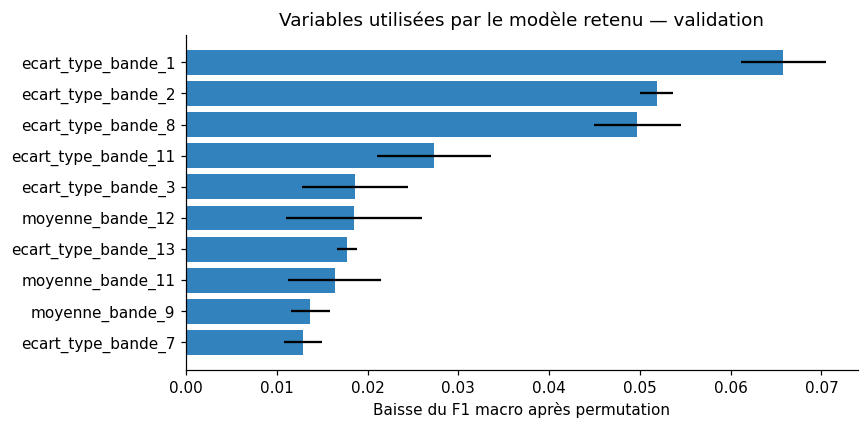

In [32]:
# Limiter le nombre d’images pour que l’interprétation reste rapide.
indices_interpretation = np.arange(len(y_val))
if len(y_val) > 600:
    indices_interpretation, _ = train_test_split(indices_interpretation, train_size=600,
                                                stratify=y_val, random_state=GRAINE)
importance = permutation_importance(modeles_validation[nom_retenu], X_val[indices_interpretation], y_val[indices_interpretation],
                                   scoring="f1_macro", n_repeats=3, random_state=GRAINE,
                                   n_jobs=1)
table_importances = pd.DataFrame({"Variable": noms_variables,
                                  "Baisse moyenne F1 macro": importance.importances_mean,
                                  "Écart-type": importance.importances_std}).sort_values("Baisse moyenne F1 macro", ascending=False)
display(table_importances.head(10).round(4))
vue = table_importances.head(10).iloc[::-1]
plt.figure(figsize=(8, 4))
plt.barh(vue.Variable, vue["Baisse moyenne F1 macro"], xerr=vue["Écart-type"], color="#3182bd")
plt.xlabel("Baisse du F1 macro après permutation")
plt.title("Variables utilisées par le modèle retenu — validation")
plt.tight_layout()
plt.show()

### Importance des caractéristiques

L’importance par permutation utilise **600 patches de validation** et **trois permutations par variable**. La pipeline a été entraînée sur l’apprentissage : les caractéristiques permutées sont transformées par son normaliseur déjà ajusté avant la prédiction.

| Variable | Baisse moyenne du F1 macro |
|---|---:|
| Écart-type de la bande 1 | 0,0658 |
| Écart-type de la bande 2 | 0,0519 |
| Écart-type de la bande 8 | 0,0497 |

Ces variables contribuent aux prédictions dans cet échantillon. Les bandes et statistiques peuvent être corrélées et se remplacer partiellement. Une faible importance individuelle ne démontre pas qu’une bande est inutile. Le calcul ne prouve pas de causalité, ne réajuste pas le normaliseur et n’utilise pas le test.

## 7. Évaluation finale sur le test réservé

Les paramètres sont fixés. Nous réentraînons la forêt aléatoire sur l’ensemble apprentissage + validation, puis enregistrons une seule série de prédictions sur le test. Les matrices, rapports et intervalles ci-dessous réutilisent ces prédictions, sans nouvel ajustement du modèle.

**Incertitude :** nous calculons un intervalle à 95 % par 1 000 rééchantillonnages des blocs géographiques du test. Cette méthode conserve ensemble les patches d’un même bloc ; l’intervalle reste conditionnel à ce jeu et à ce découpage. Il ne mesure ni toutes les incertitudes d’entraînement, ni celles d’un déploiement dans un autre domaine.

Évaluation terminée : Forêt aléatoire
Modèle unique ; paramètres fixés sur la validation : Forêt aléatoire


,Accuracy,Accuracy IC95 bas,Accuracy IC95 haut,F1 macro,F1 macro IC95 bas,F1 macro IC95 haut,Apprentissage final (s),Prédiction test (s)
Modèle,,,,,,,,
Forêt aléatoire,0.8415,0.7982,0.8772,0.836,0.7859,0.8646,10.6932,0.0785


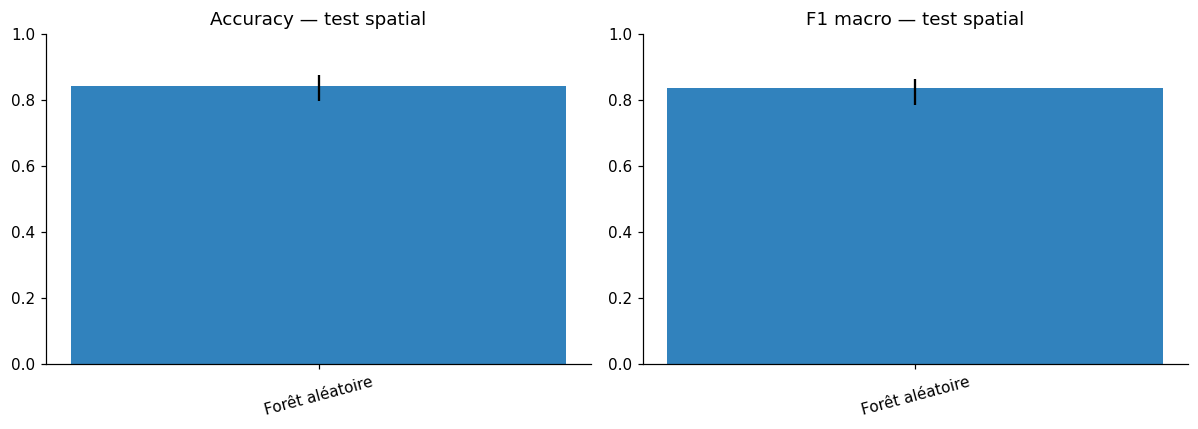

In [33]:
indices_final = np.concatenate([indices_apprentissage, indices_validation])
predictions_test, modeles_finaux, temps_finaux = {}, {}, {}
for nom, modele in modeles_validation.items():
    modele_final = clone(modele)
    debut = time.perf_counter()
    modele_final.fit(X[indices_final], y[indices_final])
    # Le normaliseur final est réajusté sur apprentissage + validation.
    normaliseur_final = modele_final.named_steps["standardscaler"]
    assert int(normaliseur_final.n_samples_seen_) == len(indices_final)
    assert np.allclose(normaliseur_final.mean_, X[indices_final].mean(axis=0))
    temps_apprentissage = time.perf_counter() - debut
    debut = time.perf_counter()
    predictions_test[nom] = modele_final.predict(X_test)
    temps_prediction = time.perf_counter() - debut
    modeles_finaux[nom] = modele_final
    temps_finaux[nom] = (temps_apprentissage, temps_prediction)
    print("Évaluation terminée :", nom)

def scores_matrice(matrice):
    # Calcul direct de l’accuracy et du F1 macro à partir d’une matrice de confusion.
    diagonale = np.diag(matrice)
    denominateurs = matrice.sum(axis=0) + matrice.sum(axis=1)
    f1 = np.divide(2*diagonale, denominateurs, out=np.zeros(len(classes)), where=denominateurs != 0)
    return diagonale.sum()/matrice.sum(), f1.mean()

blocs_test = table.loc[indices_test, "bloc"].to_numpy()
blocs_uniques = np.unique(blocs_test)
assert len(blocs_uniques) >= 5
resultats = []
for nom, predictions in predictions_test.items():
    # Constituer une matrice de confusion par bloc spatial.
    matrices = np.array([confusion_matrix(y_test[blocs_test == bloc], predictions[blocs_test == bloc], labels=classes)
                         for bloc in blocs_uniques])
    generateur = np.random.default_rng(GRAINE)
    scores_bootstrap = []
    for _ in range(1000):
        selection = generateur.integers(0, len(matrices), size=len(matrices))
        scores_bootstrap.append(scores_matrice(matrices[selection].sum(axis=0)))
    bas, haut = np.percentile(scores_bootstrap, [2.5, 97.5], axis=0)
    resultats.append({"Modèle": nom,
                      "Accuracy": accuracy_score(y_test, predictions),
                      "Accuracy IC95 bas": bas[0], "Accuracy IC95 haut": haut[0],
                      "F1 macro": f1_score(y_test, predictions, average="macro", zero_division=0),
                      "F1 macro IC95 bas": bas[1], "F1 macro IC95 haut": haut[1],
                      "Apprentissage final (s)": temps_finaux[nom][0],
                      "Prédiction test (s)": temps_finaux[nom][1]})
table_resultats = pd.DataFrame(resultats).set_index("Modèle")
display(table_resultats.round(4))
print("Modèle unique ; paramètres fixés sur la validation :", nom_retenu)

# Présenter les deux métriques et leurs intervalles pour la forêt aléatoire.
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for axe, mesure in zip(axes, ["Accuracy", "F1 macro"]):
    valeurs = table_resultats[mesure]
    axe.bar(table_resultats.index, valeurs, color="#3182bd")
    # Dessiner les bornes indépendamment du point estimé (intervalle percentile).
    positions = np.arange(len(valeurs))
    axe.vlines(positions, table_resultats[mesure+" IC95 bas"], table_resultats[mesure+" IC95 haut"], color="black")
    axe.set_ylim(0, 1)
    axe.set_title(mesure + " — test spatial")
    axe.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

,Précision,Rappel,F1,Effectif
AnnualCrop,0.771,0.795,0.783,572.000
Forest,0.953,0.992,0.972,617.000
HerbaceousVegetation,0.865,0.772,0.816,857.000
Highway,0.665,0.539,0.596,523.000
Industrial,0.870,0.930,0.899,473.000
Pasture,0.810,0.899,0.852,414.000
PermanentCrop,0.750,0.755,0.753,564.000
Residential,0.866,0.900,0.883,612.000
River,0.756,0.870,0.809,307.000
SeaLake,1.000,0.993,0.997,589.000


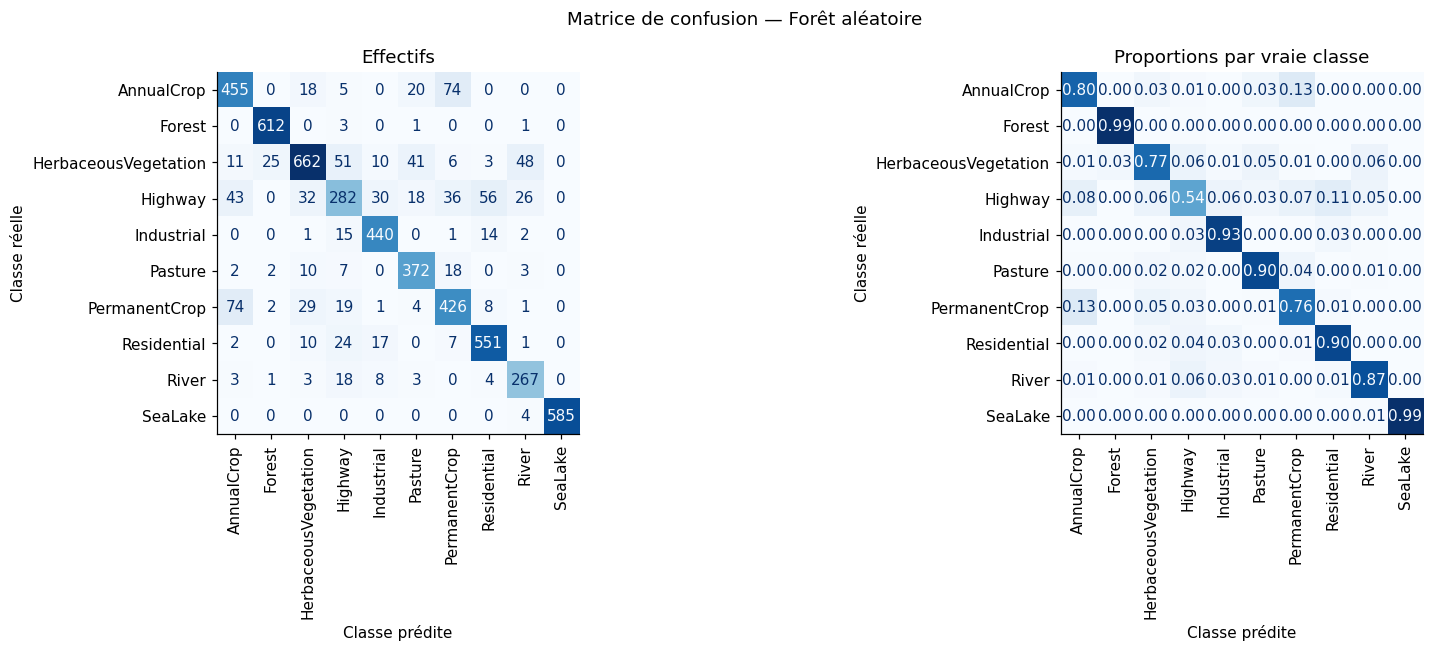

,Classe réelle,Classe prédite,Nombre,Part de la classe réelle
3,AnnualCrop,PermanentCrop,74,0.129
33,PermanentCrop,AnnualCrop,74,0.131
20,Highway,Residential,56,0.107
9,HerbaceousVegetation,Highway,51,0.060
14,HerbaceousVegetation,River,48,0.056
15,Highway,AnnualCrop,43,0.082
11,HerbaceousVegetation,Pasture,41,0.048
19,Highway,PermanentCrop,36,0.069


In [34]:
# Détailler les performances par classe du modèle retenu.
prediction_retenue = predictions_test[nom_retenu]
rapport = pd.DataFrame(classification_report(y_test, prediction_retenue, labels=classes,
                                            output_dict=True, zero_division=0)).T
display(rapport.rename(columns={"precision": "Précision", "recall": "Rappel", "f1-score": "F1", "support": "Effectif"},
                       index={"accuracy": "Accuracy", "macro avg": "Moyenne macro", "weighted avg": "Moyenne pondérée"}).round(3))

# Afficher à la fois les nombres d’erreurs et les proportions par vraie classe.
figure, axes = plt.subplots(1, 2, figsize=(16, 6))
for axe, normalisation, titre in zip(axes, [None, "true"], ["Effectifs", "Proportions par vraie classe"]):
    ConfusionMatrixDisplay.from_predictions(y_test, prediction_retenue, labels=classes,
                                           normalize=normalisation, ax=axe, cmap="Blues",
                                           colorbar=False, xticks_rotation=90,
                                           values_format="d" if normalisation is None else ".2f")
    axe.set_title(titre)
    axe.set_xlabel("Classe prédite")
    axe.set_ylabel("Classe réelle")
plt.suptitle("Matrice de confusion — " + nom_retenu)
plt.tight_layout()
plt.show()

# Lister les confusions dans chaque sens, en excluant les prédictions correctes.
matrice = confusion_matrix(y_test, prediction_retenue, labels=classes)
erreurs_classes = pd.DataFrame([
    {"Classe réelle": a, "Classe prédite": b, "Nombre": int(matrice[i,j]),
     "Part de la classe réelle": matrice[i,j]/matrice[i].sum()}
    for i,a in enumerate(classes) for j,b in enumerate(classes) if i != j and matrice[i,j] > 0
]).sort_values("Nombre", ascending=False)
display(erreurs_classes.head(8).round(3))

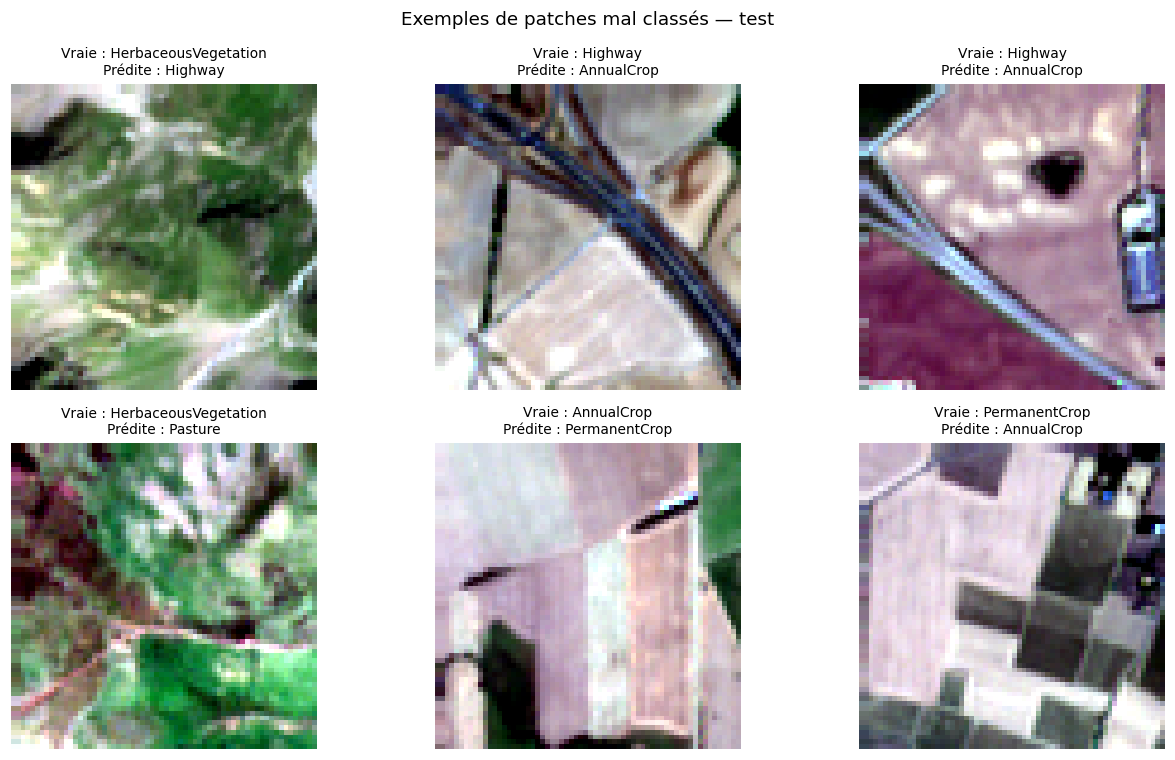

In [35]:
# Montrer jusqu’à six erreurs réelles pour comprendre les limites des statistiques.
positions_erreurs = np.flatnonzero(y_test != prediction_retenue)
if len(positions_erreurs):
    selection = np.random.default_rng(GRAINE).choice(positions_erreurs, size=min(6, len(positions_erreurs)), replace=False)
    figure, axes = plt.subplots(2, 3, figsize=(12, 7))
    for axe in axes.flat:
        axe.axis("off")
    for axe, position in zip(axes.flat, selection):
        chemin = table.loc[indices_test[position], "fichier"]
        axe.imshow(afficher_rgb(chemin))
        axe.set_title(f"Vraie : {y_test[position]}\nPrédite : {prediction_retenue[position]}", fontsize=9)
    plt.suptitle("Exemples de patches mal classés — test")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune erreur dans ce test.")

### Résultats et analyse des erreurs

Après sélection sur validation, la **pipeline entière** est réentraînée sur apprentissage + validation. Le normaliseur final apprend sur **21 139 patches**, sans inclure les **5 528 patches de test**.

| Indicateur | Résultat | Intervalle à 95 % par rééchantillonnage des blocs |
|---|---:|---|
| Accuracy | **84,15 %** | [79,82 % ; 87,72 %] |
| F1 macro | **0,836** | [0,786 ; 0,865] |
| Accuracy de la règle majoritaire (AnnualCrop) | 10,35 % | Non estimé. |

Les intervalles utilisent **1 000 rééchantillonnages des blocs géographiques**. Ils ne couvrent pas toutes les incertitudes d’entraînement ou de généralisation.

La précision mesure la part de bonnes prédictions parmi celles attribuées à une classe ; le rappel mesure la part des patches réels de cette classe retrouvés. Le F1 combine précision et rappel.

| Classe | Précision | Rappel | F1 | Patches de test |
|---|---:|---:|---:|---:|
| AnnualCrop | 0,771 | 0,795 | 0,783 | 572 |
| Forest | 0,953 | 0,992 | 0,972 | 617 |
| HerbaceousVegetation | 0,865 | 0,772 | 0,816 | 857 |
| Highway | 0,665 | 0,539 | 0,596 | 523 |
| Industrial | 0,870 | 0,930 | 0,899 | 473 |
| Pasture | 0,810 | 0,899 | 0,852 | 414 |
| PermanentCrop | 0,750 | 0,755 | 0,753 | 564 |
| Residential | 0,866 | 0,900 | 0,883 | 612 |
| River | 0,756 | 0,870 | 0,809 | 307 |
| SeaLake | 1,000 | 0,993 | 0,997 | 589 |

**SeaLake** et **Forest** ont les meilleurs F1 : **0,997** et **0,972**. La classe la plus difficile est **Highway**, avec un **F1 de 0,596** et un **rappel de 0,539**.

| Classe réelle | Classe prédite | Patches concernés |
|---|---|---:|
| AnnualCrop | PermanentCrop | 74 |
| PermanentCrop | AnnualCrop | 74 |
| Highway | Residential | 56 |
| HerbaceousVegetation | Highway | 51 |
| HerbaceousVegetation | River | 48 |

Les confusions les plus fréquentes sont **AnnualCrop → PermanentCrop** et **PermanentCrop → AnnualCrop**, avec **74 patches dans chaque sens**. Pour l’usage urbain, nous observons aussi **14 Industrial → Residential** et **17 Residential → Industrial**.

Des spectres proches, des patches mixtes et la perte de géométrie sont des explications possibles, sans preuve causale fournie par ces tableaux. Nous ne retouchons pas les paramètres d’après le test. Le même ensemble de test a été utilisé lors d’une évaluation précédente. La réévaluation après introduction de StandardScaler ne constitue donc pas une validation indépendante.

## 8. Conclusion et limites

La conclusion porte sur les performances mesurées dans le découpage spatial retenu. Les causes possibles des erreurs restent des hypothèses à vérifier, et la généralisation à d’autres conditions nécessite une évaluation indépendante.

In [36]:
# Synthétiser les performances, les erreurs et les limites du modèle.
r = table_resultats.loc[nom_retenu]
# Calculer l’accuracy de la référence majoritaire sur le test.
classe_majoritaire = pd.Series(y[indices_final]).value_counts().idxmax()
accuracy_regle_majoritaire = np.mean(y_test == classe_majoritaire)
classe_difficile = rapport.loc[classes, "f1-score"].idxmin()
principales_variables = ", ".join(table_importances.head(3).Variable)
confusion_principale = erreurs_classes.iloc[0] if len(erreurs_classes) else None
phrase_erreur = (f"La confusion la plus fréquente est **{confusion_principale['Classe réelle']} → "
                f"{confusion_principale['Classe prédite']}** ({int(confusion_principale['Nombre'])} patches)."
                if confusion_principale is not None else "Aucune confusion n’a été observée.")
conclusion = f"""
**Réponse à l’objectif.** Le modèle étudié est une **forêt aléatoire**, dont les paramètres ont été choisis sur la validation. Sur le test spatial réservé ({len(y_test):,} patches), il obtient une accuracy de **{r['Accuracy']:.1%}** et un F1 macro de **{r['F1 macro']:.3f}**. À titre de repère, prédire toujours la classe majoritaire de l’apprentissage final donnerait une accuracy de **{accuracy_regle_majoritaire:.1%}**. L’intervalle à 95 % du F1 macro, calculé par rééchantillonnage de blocs, est **[{r['F1 macro IC95 bas']:.3f} ; {r['F1 macro IC95 haut']:.3f}]**. L’écart avec ce repère permet d’évaluer l’apport des caractéristiques et du modèle dans ce protocole.

**Erreurs.** La classe ayant le F1 le plus faible est **{classe_difficile}** ({rapport.loc[classe_difficile, 'f1-score']:.3f}). {phrase_erreur} Des spectres proches, des patches mêlant plusieurs types de surface et la perte de la forme des objets sont des explications possibles ; la matrice seule ne permet pas de les prouver.

**Interprétation.** Les premières variables selon la permutation sur la validation sont **{principales_variables}**. Le modèle utilise donc des niveaux spectraux et/ou leur variation interne, ce qui est cohérent avec notre représentation des surfaces. La corrélation entre bandes et l’échantillonnage limitent l’interprétation ; on n’attribue pas une importance causale à une bande.

**Points forts et limites des données.** EuroSAT offre 27 000 images étiquetées, dix classes et treize bandes, avec un déséquilibre modéré. Les patches sont petits, parfois mixtes, et ne constituent pas une carte pixel par pixel. La séparation par blocs de 50 km et la zone tampon de 2 km réduisent la proximité spatiale, sans éliminer toute dépendance régionale ou saisonnière. Les résultats ne suffisent pas à annoncer la même performance dans un autre pays ou à une autre date.

**Points forts et limites de l’algorithme.** La pipeline applique un centrage-réduction avant la forêt aléatoire, qui représente des interactions et permet une inspection des variables. Elle peut demander de la mémoire, apprendre des particularités du jeu d’apprentissage et ses importances doivent être interprétées avec prudence. Nos 26 statistiques sont compactes ; elles perdent la disposition spatiale des pixels et peuvent manquer des structures comme les routes et les bâtiments.

**Suite proposée.** Comparer des indices spectraux et des caractéristiques de texture, tester une validation croisée par blocs pour vérifier la stabilité, puis essayer un réseau convolutif qui conserve la structure des images. Une analyse non supervisée (par exemple PCA et regroupement) pourrait montrer quelles classes se mélangent dans l’espace des caractéristiques. Toute nouvelle sélection de méthode devra utiliser la validation et une nouvelle évaluation finale indépendante.
"""
display(Markdown(conclusion))

# Enregistrer les résultats et les paramètres du prétraitement.
dossier_resultats = Path("resultats_eurosat_normalise")
dossier_resultats.mkdir(exist_ok=True)
table_resultats.to_csv(dossier_resultats / "performances_test.csv", encoding="utf-8-sig")
table_validation.to_csv(dossier_resultats / "recherche_validation.csv", index=False, encoding="utf-8-sig")
rapport.to_csv(dossier_resultats / "performances_par_classe.csv", encoding="utf-8-sig")
repartition.to_csv(dossier_resultats / "repartition_spatiale.csv", encoding="utf-8-sig")
table_importances.to_csv(dossier_resultats / "importance_variables.csv", index=False, encoding="utf-8-sig")
erreurs_classes.to_csv(dossier_resultats / "confusions.csv", index=False, encoding="utf-8-sig")
(dossier_resultats / "conclusion.md").write_text(conclusion, encoding="utf-8")
pd.DataFrame({"fichier": table.loc[indices_test, "fichier"].to_numpy(),
              "classe_reelle": y_test, "bloc": blocs_test,
              **predictions_test}).to_csv(dossier_resultats / "predictions_test.csv", index=False, encoding="utf-8-sig")
resume = {"modele_retenu": nom_retenu, "parametres": parametres_retenus,
          "effectifs": {nom: len(idx) for nom, idx in ensembles.items()},
          "minimum_global": int(table_complete.minimum.min()), "maximum_global": int(table_complete.maximum.max()),
          "doublons_retires": int(nb_copies), "ambigus_retires": int(nb_ambigus),
          "variables_principales": table_importances.head(3).Variable.to_list(),
          "classe_difficile": classe_difficile}
(dossier_resultats / "resume.json").write_text(json.dumps(resume, ensure_ascii=False, indent=2), encoding="utf-8")
# Enregistrer les paramètres appris, sans utiliser le test pour les ajuster.
table_normalisation.to_csv(dossier_resultats / "verification_normalisation.csv", index=False, encoding="utf-8-sig")
for nom_etape, normaliseur in [("apprentissage", normaliseur_validation),
                              ("final", modeles_finaux[nom_retenu].named_steps["standardscaler"])]:
    pd.DataFrame({"Variable": noms_variables, "Moyenne apprise": normaliseur.mean_,
                  "Écart-type utilisé": normaliseur.scale_}).to_csv(
        dossier_resultats / f"parametres_normalisation_{nom_etape}.csv", index=False, encoding="utf-8-sig")
resume["normalisation"] = {"methode": "StandardScaler", "ajustement_validation": "apprentissage uniquement",
                           "ajustement_final": "apprentissage + validation, sans le test"}
(dossier_resultats / "resume.json").write_text(json.dumps(resume, ensure_ascii=False, indent=2), encoding="utf-8")
print("Tableaux et paramètres de normalisation enregistrés dans", dossier_resultats)

Tableaux et paramètres de normalisation enregistrés dans resultats_eurosat_normalise



**Réponse à l’objectif.** Le modèle étudié est une **forêt aléatoire**, dont les paramètres ont été choisis sur la validation. Sur le test spatial réservé (5,528 patches), il obtient une accuracy de **84.2%** et un F1 macro de **0.836**. À titre de repère, prédire toujours la classe majoritaire de l’apprentissage final donnerait une accuracy de **10.3%**. L’intervalle à 95 % du F1 macro, calculé par rééchantillonnage de blocs, est **[0.786 ; 0.865]**. L’écart avec ce repère permet d’évaluer l’apport des caractéristiques et du modèle dans ce protocole.

**Erreurs.** La classe ayant le F1 le plus faible est **Highway** (0.596). La confusion la plus fréquente est **AnnualCrop → PermanentCrop** (74 patches). Des spectres proches, des patches mêlant plusieurs types de surface et la perte de la forme des objets sont des explications possibles ; la matrice seule ne permet pas de les prouver.

**Interprétation.** Les premières variables selon la permutation sur la validation sont **ecart_type_bande_1, ecart_type_bande_2, ecart_type_bande_8**. Le modèle utilise donc des niveaux spectraux et/ou leur variation interne, ce qui est cohérent avec notre représentation des surfaces. La corrélation entre bandes et l’échantillonnage limitent l’interprétation ; on n’attribue pas une importance causale à une bande.

**Points forts et limites des données.** EuroSAT offre 27 000 images étiquetées, dix classes et treize bandes, avec un déséquilibre modéré. Les patches sont petits, parfois mixtes, et ne constituent pas une carte pixel par pixel. La séparation par blocs de 50 km et la zone tampon de 2 km réduisent la proximité spatiale, sans éliminer toute dépendance régionale ou saisonnière. Les résultats ne suffisent pas à annoncer la même performance dans un autre pays ou à une autre date.

**Points forts et limites de l’algorithme.** La pipeline applique un centrage-réduction avant la forêt aléatoire, qui représente des interactions et permet une inspection des variables. Elle peut demander de la mémoire, apprendre des particularités du jeu d’apprentissage et ses importances doivent être interprétées avec prudence. Nos 26 statistiques sont compactes ; elles perdent la disposition spatiale des pixels et peuvent manquer des structures comme les routes et les bâtiments.

**Suite proposée.** Comparer des indices spectraux et des caractéristiques de texture, tester une validation croisée par blocs pour vérifier la stabilité, puis essayer un réseau convolutif qui conserve la structure des images. Une analyse non supervisée (par exemple PCA et regroupement) pourrait montrer quelles classes se mélangent dans l’espace des caractéristiques. Toute nouvelle sélection de méthode devra utiliser la validation et une nouvelle évaluation finale indépendante.


### Bilan de l’étude

**Réponse à l’objectif.** La pipeline **StandardScaler puis forêt aléatoire** obtient **84,15 % d’accuracy** et **0,836 de F1 macro** sur le test spatial, contre **10,35 % d’accuracy** pour la règle majoritaire (AnnualCrop). Ce résultat concerne les données et le découpage évalués. L’ajout de la normalisation ne démontre pas, à lui seul, une amélioration.

**Réussites et difficultés.** SeaLake et Forest ont les meilleurs F1 ; Highway est la classe la plus difficile (0,596). Les confusions les plus nombreuses sont **AnnualCrop → PermanentCrop** et **PermanentCrop → AnnualCrop**. Une bonne accuracy globale ne signifie pas que toutes les classes sont également fiables.

**Prétraitement et limites.** Le normaliseur apprend sur l’apprentissage pendant la sélection, puis sur apprentissage + validation pour le modèle final. Le test est uniquement transformé avec les paramètres appris. Le découpage spatial et les contrôles des doublons réduisent certains risques de résultats optimistes. Les statistiques perdent la disposition des pixels ; les patches peuvent être mixtes et les conditions d’acquisition sont limitées. Les importances ne démontrent pas de causalité.

**Suite proposée.** Étudier des indices spectraux et des caractéristiques de texture, comparer les choix sur validation, examiner leur stabilité avec une validation croisée par blocs et envisager un réseau convolutif. Une nouvelle sélection devra être suivie d’une évaluation indépendante du test déjà consulté.